# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

In [1]:
!pip install torch torchvision transformers scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: C:\Users\nguye\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
# Import thư viện và cố định seed
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch  :", torch.__version__)
print("device :", device)


torch  : 2.14.1+cpu
device : cpu


In [3]:
# Hai hàm tiện ích dùng lại trong cả notebook
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)


def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")


In [4]:
# Cấu hình chung cho cả bốn bài: đường dẫn, kích thước ảnh, batch size, seed
from pathlib import Path

DATA_ROOT = Path("VinaFood21")       
IMG_SIZE = 64
BATCH = 32
SEED = 42

HAS_DATA = (DATA_ROOT / "train").is_dir()
print("Tìm thấy dữ liệu:", HAS_DATA, "-", DATA_ROOT.resolve())


Tìm thấy dữ liệu: True - D:\UIT\DS201\Bài thực hành 2\VinaFood21


In [5]:
# Kiểm tra torchvision và chốt mean/std của ImageNet
from torch.utils.data import DataLoader

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

try:
    from torchvision import datasets, transforms
    HAS_TV = True
except ImportError:
    HAS_TV = False
    print("Chưa có torchvision.")

READY = HAS_DATA and HAS_TV
print("Sẵn sàng nạp dữ liệu:", READY)

Sẵn sàng nạp dữ liệu: True


In [6]:
# Hai bộ transform riêng: train có augment, val/test không
if HAS_TV:
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    print("Đã dựng train_tf và eval_tf.")


Đã dựng train_tf và eval_tf.


In [7]:
# Tạo dataset và DataLoader
CLASSES = [f"lop_{i}" for i in range(21)]
train_ds = val_ds = train_dl = val_dl = None

if READY:
    train_ds = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
    val_ds = datasets.ImageFolder(DATA_ROOT / "val", transform=eval_tf)
    train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
    val_dl = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2)

    CLASSES = train_ds.classes
    print("số lớp      :", len(CLASSES))
    print("số ảnh train:", len(train_ds))
    print("thứ tự lớp  :", CLASSES[:5], "...")
else:
    print("Bỏ qua phần load dữ liệu.")


số lớp      : 21
số ảnh train: 10044
thứ tự lớp  : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...


In [8]:
# Chiều tensor trước và sau DataLoader: một ảnh so với một batch
if READY:
    anh, nhan = train_ds[0]
    xb, yb = next(iter(train_dl))
    show("một ảnh sau transform", anh)
    show("một batch vào model", xb)
    show("nhãn", yb)
else:
    show("một ảnh sau transform", torch.rand(3, IMG_SIZE, IMG_SIZE))
    show("một batch vào model", torch.rand(BATCH, 3, IMG_SIZE, IMG_SIZE))
    print("(tensor giả lập, vì chưa có dữ liệu thật)")


một ảnh sau transform        (3, 64, 64)
một batch vào model          (32, 3, 64, 64)
nhãn                         (32,)


In [9]:
# Huấn luyện một epoch
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                     # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total
# Đánh giá, trả về cả y_true và y_pred để tính macro-F1 và confusion matrix
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                      # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred


### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

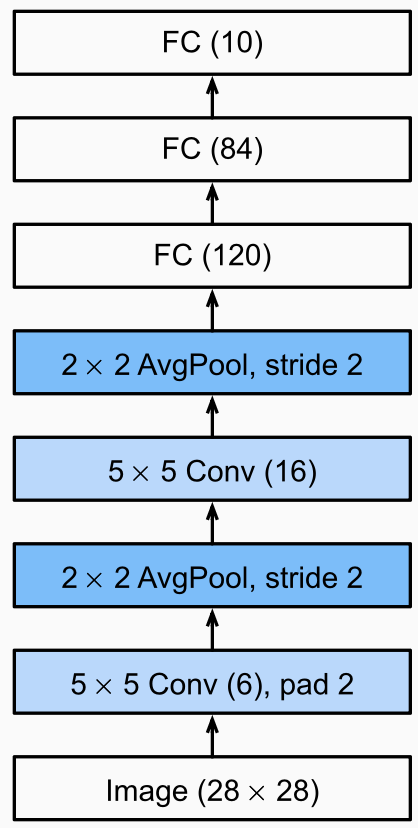

In [10]:
# Định nghĩa LeNet-5 với số channel vào, kích thước ảnh và số lớp tham số hoá
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)

        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)
        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):
        # Dò số chiều sau S4 bằng một forward giả, tránh tính tay
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)


In [11]:
# Khởi tạo cấu hình của Bài 1: ảnh 64x64x3, 21 lớp
lenet = LeNet5(in_ch=3, img=64, num_classes=21)
print("số chiều sau flatten:", lenet.n_flat)
print("tổng tham số        :", f"{n_params(lenet):,}")

assert lenet.n_flat == 2704
assert n_params(lenet) == 339_421


số chiều sau flatten: 2704
tổng tham số        : 339,421


In [12]:
# Hàm dựng bảng shape và tham số của từng layer
def layer_table(model, img, in_ch=3):
    x = torch.zeros(1, in_ch, img, img)
    rows, total = [], 0
    for name, layer in [("C1", model.c1), ("S2", model.s2),
                        ("C3", model.c3), ("S4", model.s4)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, "x".join(map(str, tuple(x.shape)[1:])), p))
    x = x.flatten(1)
    rows.append(("flatten", str(x.shape[1]), 0))
    for name, layer in [("F5", model.f5), ("F6", model.f6), ("OUT", model.out)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, str(x.shape[1]), p))
    return rows, total
# In bảng cho cấu hình ảnh 64x64
rows, total = layer_table(lenet, 64)

print(f"{'layer':<10}{'output':<16}{'tham số':>12}")
for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")
print(f"{'TỔNG':<10}{'':<16}{total:>12,}")
assert total == 339_421

# Nhận xét: tham số dồn gần hết vào F5, hai conv layer rất nhẹ


layer     output               tham số
C1        6x60x60                  456
S2        6x30x30                    0
C3        16x26x26               2,416
S4        16x13x13                   0
flatten   2704                       0
F5        120                  324,600
F6        84                    10,164
OUT       21                     1,785
TỔNG                           339,421


In [13]:
# So sánh cấu hình ảnh 32x32 và 64x64
print(f"{'resize':<10}{'sau S4':<14}{'flatten':>9}{'F5':>12}{'tổng':>12}{'conv %':>9}")
for img in (32, 64):
    m = LeNet5(in_ch=3, img=img, num_classes=21)
    conv_p = n_params(m.c1) + n_params(m.c3)
    side = int((m.n_flat // 16) ** 0.5)
    print(f"{img}x{img:<5}{f'{side}x{side}x16':<14}{m.n_flat:>9,}"
          f"{n_params(m.f5):>12,}{n_params(m):>12,}"
          f"{100 * conv_p / n_params(m):>8.2f}%")


resize    sau S4          flatten          F5        tổng   conv %
32x32   5x5x16              400      48,120      62,941    4.56%
64x64   13x13x16          2,704     324,600     339,421    0.85%


In [14]:
# Kiểm tra: phần conv giữ nguyên, chỉ phần fully connected phình ra
m32, m64 = LeNet5(img=32), LeNet5(img=64)

assert n_params(m32) == 62_941 and n_params(m64) == 339_421
assert n_params(m32.c1) + n_params(m32.c3) == 2872
assert n_params(m64.c1) + n_params(m64.c3) == 2872

print(f"Tổng tham số gấp {n_params(m64) / n_params(m32):.2f} lần,"
      " hai conv layer vẫn 2,872.")


Tổng tham số gấp 5.39 lần, hai conv layer vẫn 2,872.


In [15]:
# BatchNorm2d có 2 tham số học được cho mỗi channel (gamma, beta)
bn = nn.BatchNorm2d(64)
print("BatchNorm2d(64):", n_params(bn), "tham số = 2 * 64")
assert n_params(bn) == 128


BatchNorm2d(64): 128 tham số = 2 * 64


In [16]:
# Dropout cho kết quả khác nhau ở train và giống nhau ở eval
net = nn.Sequential(nn.Linear(10, 10), nn.Dropout(p=0.5))
x = torch.ones(4, 10)

net.train()
a, b = net(x), net(x)
print("model.train(): hai lần forward giống nhau?", torch.equal(a, b))

net.eval()
a, b = net(x), net(x)
print("model.eval() : hai lần forward giống nhau?", torch.equal(a, b))

# Nhận xét: quên eval() thì mỗi lần đánh giá ra một con số khác mà không báo lỗi


model.train(): hai lần forward giống nhau? False
model.eval() : hai lần forward giống nhau? True


In [17]:
# Chạy thử đúng một batch qua LeNet trước khi huấn luyện cả epoch
xb = next(iter(train_dl))[0] if READY else torch.rand(BATCH, 3, IMG_SIZE, IMG_SIZE)

lenet.eval()
with torch.no_grad():
    logits = lenet(xb)

show("input", xb)
show("logits", logits)
assert logits.shape == (xb.shape[0], 21)


input                        (32, 3, 64, 64)
logits                       (32, 21)


# LeNet dùng AvgPool2d(2, 2)

In [23]:
# Vòng huấn luyện: bỏ chú thích khi đã có dữ liệu

EPOCHS = 20
model_1 = LeNet5(in_ch=3, img=IMG_SIZE, num_classes=len(CLASSES), pool='avg').to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1.parameters(), lr=1e-3)

lich_su = []
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model_1, train_dl, criterion, optimizer, device)
    va_loss, va_acc, _, _ = evaluate(model_1, val_dl, criterion, device)
    lich_su.append((ep, tr_loss, va_loss))
    print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}"
          f"   val {va_loss:.4f}/{va_acc:.4f}")


epoch  1  train 2.8323/0.1420   val 2.6853/0.1745
epoch  2  train 2.6601/0.1917   val 2.5649/0.2058
epoch  3  train 2.5063/0.2336   val 2.5291/0.2194
epoch  4  train 2.4295/0.2589   val 2.4250/0.2567
epoch  5  train 2.3465/0.2759   val 2.4143/0.2679
epoch  6  train 2.2690/0.3050   val 2.3447/0.2861
epoch  7  train 2.2128/0.3164   val 2.3529/0.2808
epoch  8  train 2.1715/0.3294   val 2.3232/0.2840
epoch  9  train 2.1180/0.3447   val 2.3041/0.2978
epoch 10  train 2.0916/0.3546   val 2.3072/0.3020
epoch 11  train 2.0322/0.3685   val 2.2857/0.3155
epoch 12  train 2.0173/0.3755   val 2.2870/0.3035
epoch 13  train 1.9678/0.3975   val 2.2492/0.3218
epoch 14  train 1.9601/0.3930   val 2.2992/0.3084
epoch 15  train 1.9252/0.4046   val 2.2696/0.3197
epoch 16  train 1.8941/0.4124   val 2.2342/0.3182
epoch 17  train 1.8809/0.4120   val 2.2610/0.3200
epoch 18  train 1.8635/0.4207   val 2.2575/0.3134
epoch 19  train 1.8527/0.4218   val 2.2680/0.3182
epoch 20  train 1.8297/0.4326   val 2.2679/0.3188


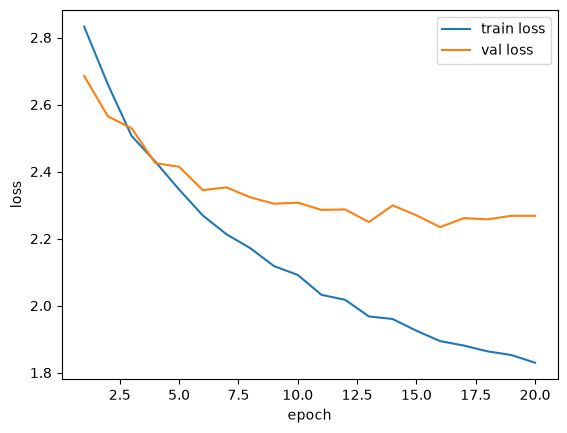

                  precision    recall  f1-score   support

        banh-can     0.2212    0.1037    0.1412       241
        banh-hoi     0.2956    0.4778    0.3652       607
    banh-mi-chao     0.3740    0.3287    0.3499       289
        banh-tet     0.3191    0.3077    0.3133       364
 banh-trang-tron     0.2112    0.1715    0.1893       309
          banh-u     0.3333    0.1932    0.2446       176
        banh-uot     0.2587    0.3446    0.2956       560
       bap-nuong     0.1739    0.0559    0.0847       143
          bo-kho     0.3595    0.3521    0.3558       338
       bo-la-lot     0.5067    0.4934    0.5000       458
       bot-chien     0.2056    0.2391    0.2211       276
           ca-ri     0.4048    0.0994    0.1596       171
    canh-kho-qua     0.4635    0.5690    0.5108       290
   canh-khoai-mo     0.7790    0.7121    0.7441       198
        ga-nuong     0.2352    0.2769    0.2543       372
          goi-ga     0.2848    0.2966    0.2905       290
          ha-

<Axes: >

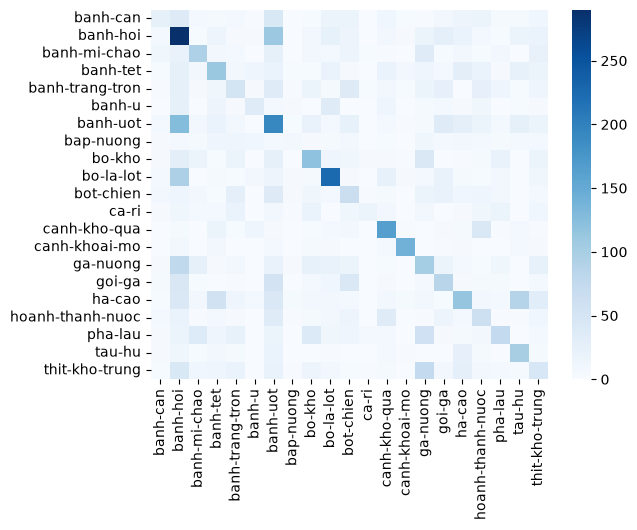

In [24]:
# Vẽ loss train và val để thấy điểm hai đường tách nhau

import matplotlib.pyplot as plt
ep, tr, va = zip(*lich_su)
plt.plot(ep, tr, label="train loss")
plt.plot(ep, va, label="val loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()
# Đo lường: macro-F1 là độ đo chính của cả bốn bài

from sklearn.metrics import classification_report, confusion_matrix, f1_score

_, _, y_true, y_pred = evaluate(model_1, val_dl, criterion, device)
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
print("macro-F1:", f1_score(y_true, y_pred, average="macro"))

import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")


# LeNet dùng MaxPool2d(2, 2)

In [26]:
# Vòng huấn luyện: bỏ chú thích khi đã có dữ liệu

EPOCHS = 20
model_2 = LeNet5(in_ch=3, img=IMG_SIZE, num_classes=len(CLASSES), pool='max').to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2.parameters(), lr=1e-3)

lich_su = []
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model_2, train_dl, criterion, optimizer, device)
    va_loss, va_acc, _, _ = evaluate(model_2, val_dl, criterion, device)
    lich_su.append((ep, tr_loss, va_loss))
    print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}"
          f"   val {va_loss:.4f}/{va_acc:.4f}")


epoch  1  train 2.8150/0.1437   val 2.6628/0.1841
epoch  2  train 2.5976/0.2062   val 2.5014/0.2363
epoch  3  train 2.4550/0.2510   val 2.4614/0.2408
epoch  4  train 2.3610/0.2756   val 2.3961/0.2658
epoch  5  train 2.2773/0.2974   val 2.3330/0.2942
epoch  6  train 2.2138/0.3222   val 2.3070/0.2837
epoch  7  train 2.1658/0.3328   val 2.2982/0.2999
epoch  8  train 2.1166/0.3439   val 2.3447/0.2905
epoch  9  train 2.0669/0.3667   val 2.2956/0.3077
epoch 10  train 2.0370/0.3733   val 2.3616/0.2945
epoch 11  train 1.9985/0.3885   val 2.3132/0.3089
epoch 12  train 1.9748/0.3920   val 2.2919/0.3105
epoch 13  train 1.9517/0.3968   val 2.2743/0.3189
epoch 14  train 1.9331/0.4010   val 2.2394/0.3215
epoch 15  train 1.8977/0.4145   val 2.2555/0.3182
epoch 16  train 1.8663/0.4264   val 2.2326/0.3294
epoch 17  train 1.8495/0.4298   val 2.2439/0.3282
epoch 18  train 1.8422/0.4268   val 2.2657/0.3276
epoch 19  train 1.8314/0.4310   val 2.2327/0.3352
epoch 20  train 1.8112/0.4342   val 2.2523/0.3265


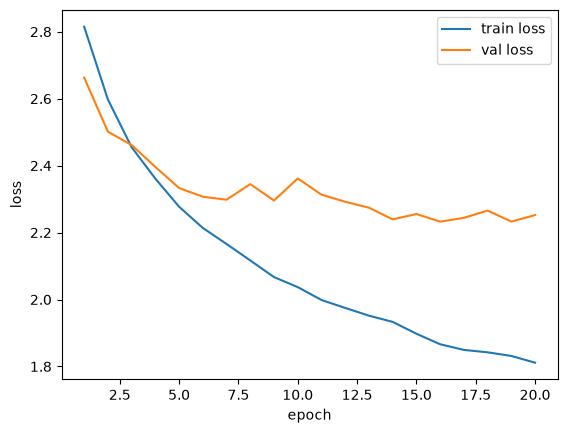

                  precision    recall  f1-score   support

        banh-can     0.1822    0.1950    0.1884       241
        banh-hoi     0.3912    0.4119    0.4013       607
    banh-mi-chao     0.2611    0.5709    0.3583       289
        banh-tet     0.3446    0.3352    0.3398       364
 banh-trang-tron     0.2287    0.1650    0.1917       309
          banh-u     0.4118    0.1591    0.2295       176
        banh-uot     0.3739    0.1589    0.2231       560
       bap-nuong     0.1618    0.0769    0.1043       143
          bo-kho     0.3680    0.2515    0.2988       338
       bo-la-lot     0.5089    0.5590    0.5328       458
       bot-chien     0.2314    0.2935    0.2588       276
           ca-ri     0.2677    0.1988    0.2282       171
    canh-kho-qua     0.5364    0.6103    0.5710       290
   canh-khoai-mo     0.7263    0.6970    0.7113       198
        ga-nuong     0.2654    0.2903    0.2773       372
          goi-ga     0.3500    0.1690    0.2279       290
          ha-

<Axes: >

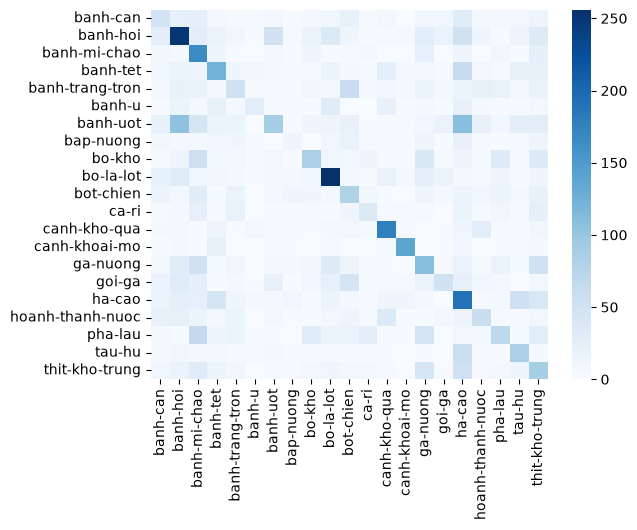

In [27]:
# Vẽ loss train và val để thấy điểm hai đường tách nhau

import matplotlib.pyplot as plt
ep, tr, va = zip(*lich_su)
plt.plot(ep, tr, label="train loss")
plt.plot(ep, va, label="val loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()
# Đo lường: macro-F1 là độ đo chính của cả bốn bài

from sklearn.metrics import classification_report, confusion_matrix, f1_score

_, _, y_true, y_pred = evaluate(model_2, val_dl, criterion, device)
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
print("macro-F1:", f1_score(y_true, y_pred, average="macro"))

import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")


### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

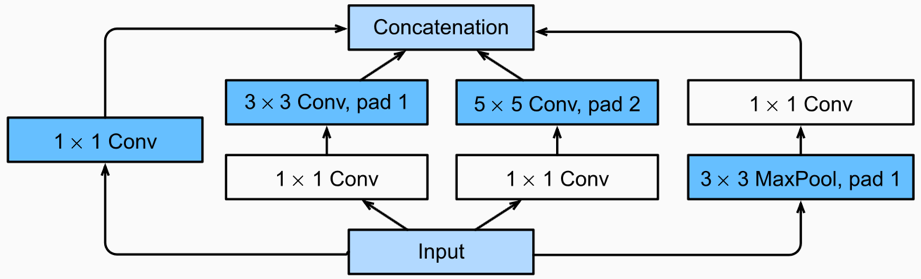

**GoogLeNet (Multi-branch Network)**

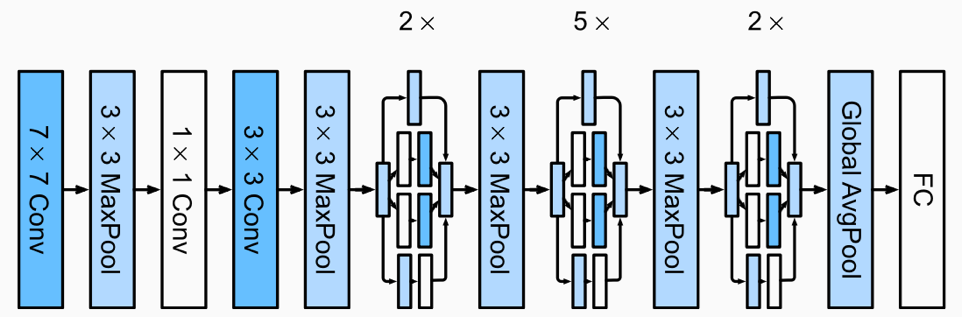

In [13]:
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.expected_out_channels = f1 + f3 + f5 + fp
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x),
                          self.b3(x), self.b4(x)], dim=1)

In [15]:
class MiniGoogLeNet(nn.Module):
    def __init__(self, in_ch=3, num_classes=21, num_blocks=3):
        super().__init__()
        assert num_blocks in [3, 4]
        self.num_blocks = num_blocks

        # Stem: Conv 3x3 chuyển từ 3 channels -> 64 channels
        self.stem = nn.Sequential(
            nn.Conv2d(in_ch, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True)
        )

        # Block 1: in_ch=64 -> out_ch=16+24+8+8=56
        self.block1 = InceptionBlock(64, f1=16, f3r=16, f3=24, f5r=4, f5=8, fp=8)
        self.pool1 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # Block 2: in_ch=56 -> out_ch=32+48+16+16=112 (Khớp chính xác B.4 Bước 3)
        self.block2 = InceptionBlock(56, f1=32, f3r=32, f3=48, f5r=8, f5=16, fp=16)
        self.pool2 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # Block 3: in_ch=112 -> out_ch=64+96+32+32=224
        self.block3 = InceptionBlock(112, f1=64, f3r=64, f3=96, f5r=16, f5=32, fp=32)

        if num_blocks == 4:
            # Block 4: in_ch=224 -> out_ch=64+96+32+32=224
            self.block4 = InceptionBlock(224, f1=64, f3r=64, f3=96, f5r=16, f5=32, fp=32)
            self.pool3 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
            final_channels = 224
        else:
            self.block4 = None
            self.pool3 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
            final_channels = 224

        # Phân loại: Dùng Global Average Pooling thay vì Flatten
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.4)
        self.classifier = nn.Linear(final_channels, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.block1(x))
        x = self.pool2(self.block2(x))
        x = self.block3(x)
        if self.block4 is not None:
            x = self.block4(x)
        x = self.pool3(x)

        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.classifier(x)

    def get_block_info(self, sample_input=None):
        """
        Trích xuất thông tin output shape và số channel lý thuyết vs thực tế của từng block.
        """
        device = next(self.parameters()).device
        if sample_input is None:
            sample_input = torch.zeros(1, 3, 64, 64, device=device)
        else:
            sample_input = sample_input.to(device)

        info = []
        with torch.no_grad():
            x = self.stem(sample_input)
            info.append(("Stem Conv (3->64)", tuple(x.shape), 64, 64, n_params(self.stem)))

            # Block 1
            x = self.block1(x)
            info.append(("Inception Block 1 (64->56)", tuple(x.shape),
                         self.block1.expected_out_channels, x.shape[1], n_params(self.block1)))
            x = self.pool1(x)

            # Block 2
            x = self.block2(x)
            info.append(("Inception Block 2 (56->112)", tuple(x.shape),
                         self.block2.expected_out_channels, x.shape[1], n_params(self.block2)))
            x = self.pool2(x)

            # Block 3
            x = self.block3(x)
            info.append(("Inception Block 3 (112->224)", tuple(x.shape),
                         self.block3.expected_out_channels, x.shape[1], n_params(self.block3)))

            # Block 4 nếu có
            if self.block4 is not None:
                x = self.block4(x)
                info.append(("Inception Block 4 (224->224)", tuple(x.shape),
                             self.block4.expected_out_channels, x.shape[1], n_params(self.block4)))
            x = self.pool3(x)

            x = self.gap(x)
            info.append(("GlobalAvgPool2d(1)", tuple(x.shape), x.shape[1], x.shape[1], 0))

            x = torch.flatten(x, 1)
            logits = self.classifier(self.dropout(x))
            info.append(("Classifier (FC)", tuple(logits.shape), logits.shape[1], logits.shape[1], n_params(self.classifier)))

        return info


def n_params(module):
    return sum(p.numel() for p in module.parameters())


def print_block_channel_analysis(model):
    """In bảng phân tích đối chiếu channel lý thuyết (tính tay) và code."""
    info = model.get_block_info()
    print("=" * 80)
    print(f"{'Tên tầng / Khối':<30}{'Output Shape':<18}{'C_lý_thuyết':>12}{'C_thực_tế':>10}{'Tham số':>10}")
    print("=" * 80)
    for name, shape, c_theory, c_actual, params in info:
        print(f"{name:<30}{str(shape):<18}{c_theory:>12}{c_actual:>10}{params:>10,}")
    print("=" * 80)
    print(f"Tổng số tham số toàn mạng: {n_params(model):,}")


if __name__ == "__main__":
    print("=== KIỂM TRA MÔ HÌNH GOOGLENET RÚT GỌN (3 INCEPTION BLOCKS) ===")
    model = MiniGoogLeNet(in_ch=3, num_classes=21, num_blocks=3)
    print_block_channel_analysis(model)

=== KIỂM TRA MÔ HÌNH GOOGLENET RÚT GỌN (3 INCEPTION BLOCKS) ===
Tên tầng / Khối               Output Shape       C_lý_thuyết C_thực_tế   Tham số
Stem Conv (3->64)             (1, 64, 64, 64)             64        64     1,792
Inception Block 1 (64->56)    (1, 56, 64, 64)             56        56     7,148
Inception Block 2 (56->112)   (1, 112, 32, 32)           112       112    22,104
Inception Block 3 (112->224)  (1, 224, 16, 16)           224       224    88,112
GlobalAvgPool2d(1)            (1, 224, 1, 1)             224       224         0
Classifier (FC)               (1, 21)                     21        21     4,725
Tổng số tham số toàn mạng: 123,881


# Chạy thiết kế 3 block

In [ ]:

EPOCHS = 20
model_googlenet = MiniGoogLeNet(in_ch=3, num_classes=len(CLASSES), num_blocks=3).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_googlenet.parameters(), lr=1e-3)

lich_su = []
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model_googlenet, train_dl, criterion, optimizer, device)
    va_loss, va_acc, _, _ = evaluate(model_googlenet, val_dl, criterion, device)
    lich_su.append((ep, tr_loss, va_loss))
    print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}"
          f"   val {va_loss:.4f}/{va_acc:.4f}")

epoch  1  train 2.8985/0.1120   val 2.7332/0.1543
epoch  2  train 2.6352/0.1863   val 2.5894/0.2151
epoch  3  train 2.4785/0.2324   val 2.5240/0.2339
epoch  4  train 2.3906/0.2616   val 2.3447/0.2676
epoch  5  train 2.2846/0.2963   val 2.3044/0.2932
epoch  6  train 2.2252/0.3150   val 2.2924/0.3007
epoch  7  train 2.1535/0.3386   val 2.2238/0.3224
epoch  8  train 2.0967/0.3574   val 2.1360/0.3448
epoch  9  train 2.0595/0.3607   val 2.0784/0.3584
epoch 10  train 2.0147/0.3734   val 2.0560/0.3640
epoch 11  train 1.9814/0.3877   val 2.0490/0.3683
epoch 12  train 1.9420/0.3990   val 1.9973/0.3812
epoch 13  train 1.9208/0.4033   val 2.0006/0.3867
epoch 14  train 1.8953/0.4179   val 1.9242/0.4054
epoch 15  train 1.8473/0.4236   val 1.9517/0.3951
epoch 16  train 1.8461/0.4281   val 1.9145/0.4075
epoch 17  train 1.8258/0.4319   val 1.9437/0.4030
epoch 18  train 1.7981/0.4370   val 1.9270/0.4024
epoch 19  train 1.7881/0.4460   val 1.9313/0.4042
epoch 20  train 1.7533/0.4539   val 1.8402/0.4259


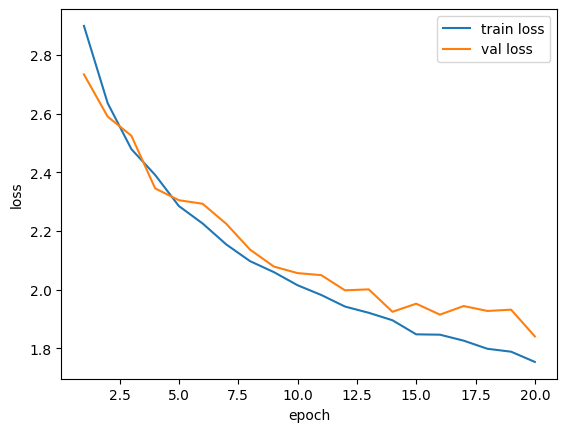

                  precision    recall  f1-score   support

        banh-can     0.3871    0.2490    0.3030       241
        banh-hoi     0.3873    0.6820    0.4940       607
    banh-mi-chao     0.5714    0.3599    0.4416       289
        banh-tet     0.4960    0.5137    0.5047       364
 banh-trang-tron     0.2962    0.3010    0.2986       309
          banh-u     0.2857    0.2386    0.2601       176
        banh-uot     0.4256    0.4036    0.4143       560
       bap-nuong     0.3860    0.1538    0.2200       143
          bo-kho     0.4151    0.4556    0.4344       338
       bo-la-lot     0.5548    0.7183    0.6261       458
       bot-chien     0.2667    0.3043    0.2843       276
           ca-ri     0.4194    0.1520    0.2232       171
    canh-kho-qua     0.4734    0.6138    0.5345       290
   canh-khoai-mo     0.7150    0.7727    0.7427       198
        ga-nuong     0.4269    0.2903    0.3456       372
          goi-ga     0.3162    0.4241    0.3623       290
          ha-

<Axes: >

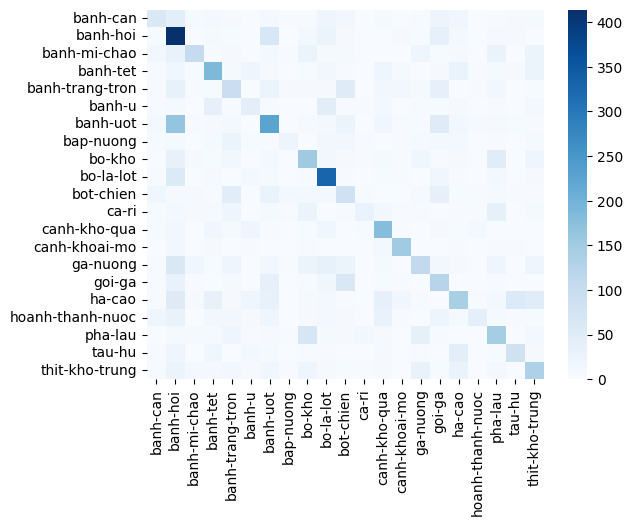

In [17]:
import matplotlib.pyplot as plt
ep, tr, va = zip(*lich_su)
plt.plot(ep, tr, label="train loss")
plt.plot(ep, va, label="val loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()
# Đo lường: macro-F1 là độ đo chính của cả bốn bài

from sklearn.metrics import classification_report, confusion_matrix, f1_score

_, _, y_true, y_pred = evaluate(model_googlenet, val_dl, criterion, device)
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
print("macro-F1:", f1_score(y_true, y_pred, average="macro"))

import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")